# 15 · Congestion maps: where and when the graph helps

**Objective.** The brief asks for congestion maps. Turn the test-set forecasts back into the road network: what the freeway looked like at the worst moment of the test period, what each model said 60 minutes earlier, and which sensors gain most from the graph.

**How the moment is chosen (no cherry-picking).** The rule uses only the *observed* speeds, never a model's error: the test weekday with the lowest mean network speed between 15:00 and 19:00, and on that day the 5-minute step with the lowest mean speed.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from src import preprocessing as pp, visualization as viz, evaluation as ev
from src.graph_utils import load_graph_artifacts
from deep_learning.dl import results

viz.apply_style()
ctx = pp.load_context()
graph = load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
keys = ["persistence", "xgboost_spatial", "dl_st_gat_noedge_s42", "dl_st_gat_s42", "dl_dcrnn_s42"]
preds, y, ymask, origins, horizons, _ = ev.load_aligned(keys, "test", ctx.speed, ctx.mask)
valid = ev.common_valid_mask(preds, ymask)
H60 = list(horizons).index(12)
ts = ctx.timestamps
src, dst = np.nonzero((graph.adjacency > 0) & ~np.eye(len(lat), dtype=bool))
segments = np.stack([np.c_[lon[src], lat[src]], np.c_[lon[dst], lat[dst]]], axis=1)

In [3]:
test_rows = np.arange(origins.min() + 12, origins.max() + 13)          # every target time in the test period
speed = np.where(ctx.mask, ctx.speed, np.nan)
frame = pd.DataFrame({"t": ts[test_rows], "mean_speed": pd.DataFrame(speed[test_rows]).mean(axis=1).to_numpy(),
                      "observed": ctx.mask[test_rows].mean(1)}, index=test_rows)
pm = frame[(frame.t.dt.dayofweek < 5) & frame.t.dt.hour.between(15, 18) & (frame.observed > .9)]
worst_day = pm.groupby(pm.t.dt.date).mean_speed.mean().idxmin()
day = pm[pm.t.dt.date == worst_day]
target = int(day.mean_speed.idxmin())
origin = target - 12
s = int(np.flatnonzero(origins == origin)[0])
print(f"worst test weekday afternoon: {worst_day:%A %d %B %Y}; slowest step {ts[target]:%H:%M} "
      f"(network mean {frame.mean_speed[target]:.1f} mph); forecasts issued at {ts[origin]:%H:%M}")

worst test weekday afternoon: Friday 15 June 2012; slowest step 16:45 (network mean 39.5 mph); forecasts issued at 15:45


## 1 · The network at its slowest moment, and three 60-minute forecasts of it

Green = free flow, red = jammed. Grey dots were sensors with no observation at that time. Every forecast panel was made **60 minutes before** the moment shown, using only data up to then.

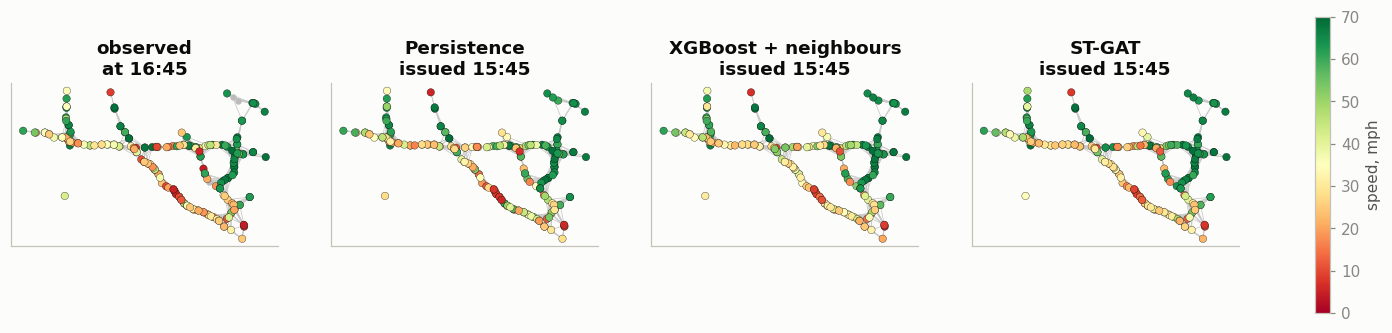

Persistence              MAE on this snapshot: 7.05 mph
XGBoost + neighbours     MAE on this snapshot: 6.50 mph
ST-GAT, edges removed    MAE on this snapshot: 6.89 mph
ST-GAT                   MAE on this snapshot: 6.32 mph
DCRNN                    MAE on this snapshot: 5.76 mph


In [4]:
def network(ax, values, title, cmap="RdYlGn", vmin=0, vmax=70):
    ax.add_collection(LineCollection(segments, colors="#c8c8c8", linewidths=.5, zorder=1))
    ok = np.isfinite(values)
    ax.scatter(lon[~ok], lat[~ok], s=10, c="#bbbbbb", zorder=2)
    sc = ax.scatter(lon[ok], lat[ok], s=24, c=values[ok], cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="k", linewidths=.2, zorder=3)
    ax.set(title=title, xticks=[], yticks=[]); ax.set_aspect(1 / np.cos(np.deg2rad(lat.mean())))
    return sc

actual = np.where(ctx.mask[target], ctx.speed[target], np.nan)
panels = [(actual, f"observed\nat {ts[target]:%H:%M}")] + [
    (preds[k][s, H60], f"{results.label(k)}\nissued {ts[origin]:%H:%M}") for k in ("persistence", "xgboost_spatial", "dl_st_gat_s42")]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (v, t_) in zip(axes, panels):
    sc = network(ax, v, t_)
fig.colorbar(sc, ax=axes, shrink=.7, label="speed, mph"); plt.show()

ok = np.isfinite(actual)
for k in ("persistence", "xgboost_spatial", "dl_st_gat_noedge_s42", "dl_st_gat_s42", "dl_dcrnn_s42"):
    print(f"{results.label(k):24s} MAE on this snapshot: {np.abs(preds[k][s, H60] - actual)[ok].mean():.2f} mph")

One snapshot is an illustration, not evidence: the table in notebook 14 is the evidence. Persistence simply copies the map from an hour earlier. Every learned model beats it on this snapshot, but the margins are small (5.8–6.9 vs 7.1 mph) and here DCRNN, not ST-GAT, is best: a single moment does not rank models.

## 2 · That afternoon at the slowest sensor

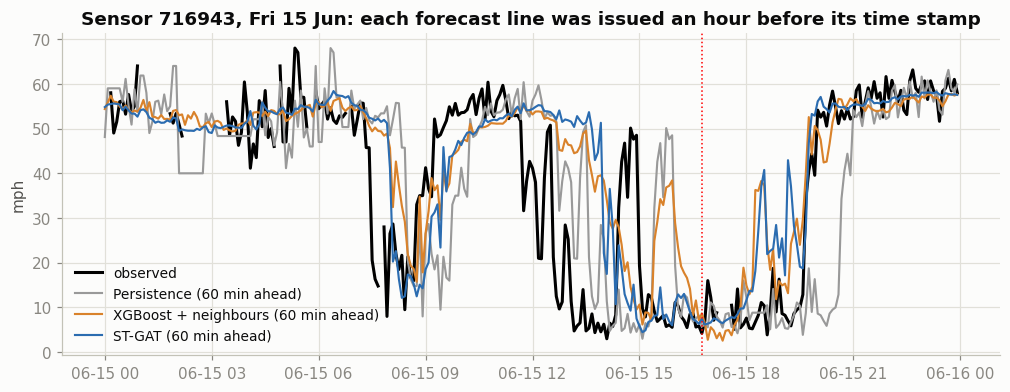

In [5]:
day_rows = np.flatnonzero(ts.normalize() == pd.Timestamp(worst_day))
day_rows = day_rows[(day_rows - 12 >= origins.min()) & (day_rows - 12 <= origins.max())]
node = int(np.nanargmin(actual))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ts[day_rows], np.where(ctx.mask[day_rows, node], ctx.speed[day_rows, node], np.nan), "k", lw=2, label="observed")
for k, c in (("persistence", "#999999"), ("xgboost_spatial", "#d9822b"), ("dl_st_gat_s42", "#2b6cb0")):
    idx = np.searchsorted(origins, day_rows - 12)
    ax.plot(ts[day_rows], preds[k][idx, H60, node], c=c, lw=1.4, label=f"{results.label(k)} (60 min ahead)")
ax.axvline(ts[target], c="r", ls=":", lw=1)
ax.set(ylabel="mph", title=f"Sensor {ctx.sensor_ids[node]}, {worst_day:%a %d %b}: each forecast line was issued an hour before its time stamp")
ax.legend(fontsize=9); plt.show()

**Reading it.** At this jammed sensor no model sees the sudden drops an hour ahead; all three lag them. The learned models do anticipate the *recovery* (around 18:30–19:30) earlier than persistence, which only reacts after the fact.

## 3 · Which sensors gain from the graph?

Per-sensor test MAE at 60 minutes, over the whole test period. Blue = the graph model is better there. Saved as `artifacts/metrics/dl_sensor_gain_60min.csv` for the presentation.

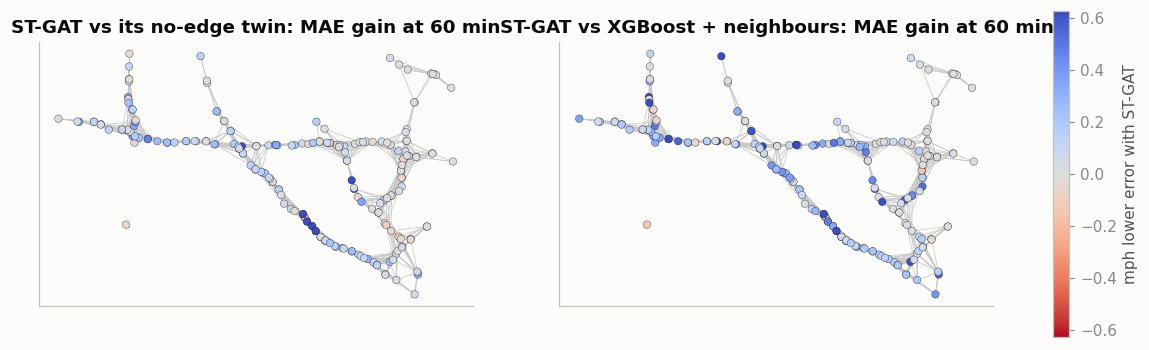

graph helps at 76% of sensors; beats XGBoost + neighbours at 82%
correlation of graph gain with in-degree: 0.10


,sensor_id,in_degree,mae_dl_st_gat_noedge_s42,mae_dl_st_gat_s42,graph_gain
node,,,,,
159,717466,14,8.967,8.051,0.916
206,769373,11,7.112,6.263,0.850
61,773939,3,7.760,6.934,0.825
155,717468,14,8.715,7.928,0.787
25,716960,3,7.630,6.905,0.725


In [6]:
per = {k: ev.per_sensor_metrics(preds[k], y, valid, horizons, ctx.sensor_ids).query("horizon_steps == 12").set_index("node").MAE
       for k in keys}
gain = pd.DataFrame({f"mae_{k}": v for k, v in per.items()})
gain.insert(0, "sensor_id", ctx.sensor_ids)
gain["graph_gain"] = gain["mae_dl_st_gat_noedge_s42"] - gain["mae_dl_st_gat_s42"]
gain["vs_xgb_spatial"] = gain["mae_xgboost_spatial"] - gain["mae_dl_st_gat_s42"]
gain["in_degree"] = (graph.adjacency > 0).sum(0) - 1
gain.round(4).to_csv(config.ARTIFACTS / "metrics" / "dl_sensor_gain_60min.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
lim = np.nanpercentile(np.abs(gain[["graph_gain", "vs_xgb_spatial"]]), 95)
for ax, col, t_ in zip(axes, ("graph_gain", "vs_xgb_spatial"),
                       ("ST-GAT vs its no-edge twin", "ST-GAT vs XGBoost + neighbours")):
    sc = network(ax, gain[col].to_numpy(), f"{t_}: MAE gain at 60 min", cmap="coolwarm_r", vmin=-lim, vmax=lim)
fig.colorbar(sc, ax=axes, shrink=.7, label="mph lower error with ST-GAT"); plt.show()
print(f"graph helps at {(gain.graph_gain > 0).mean():.0%} of sensors; beats XGBoost + neighbours at {(gain.vs_xgb_spatial > 0).mean():.0%}")
print(f"correlation of graph gain with in-degree: {gain[['graph_gain', 'in_degree']].corr().iloc[0, 1]:.2f}")
display(gain.nlargest(5, "graph_gain")[["sensor_id", "in_degree", "mae_dl_st_gat_noedge_s42", "mae_dl_st_gat_s42", "graph_gain"]].round(3))

## 4 · What was *not* built, and why

**Graph WaveNet-lite** was the optional rung 4. It was not built: ST-GAT and DCRNN already land within the published range (notebook 14), the ablation already answers the brief's question, and a fourth graph model would mostly add tuning time. Its two ideas (a learned adjacency and dilated temporal convolutions) are listed as future work.

**Signal control.** Nothing here controls traffic. The optional SUMO study in `phase2/simulation` is a simulation only.

## Common mistakes

* **Choosing the snapshot by model error.** Picking the moment where your model looks best is cherry-picking. The rule above looks only at observed speeds.
* **Plotting the forecast at the time it was issued.** A 60-minute forecast belongs at `origin + 60 min`; drawing it at the origin makes every model look prescient.
* **Reading one map as evidence.** It illustrates; the 6,901-window table decides.

## Check yourself

1. Why is persistence's map simply the observed map from an hour earlier?
2. A sensor with zero upstream edges cannot gain from upstream attention. Where would you expect it on the gain map?
3. Why save per-sensor numbers to a CSV instead of recomputing them in the presentation?